# SakAI Final Demo

**Main message.** SakAI investigates whether satellite-based crop classifiers trained using external datasets can identify crops in new agricultural regions, and whether adding a small number of regional crop-reference fields can improve their performance.

Our long-term goal is to apply this approach to carrot, cabbage, and potato classification in Paoay, Atok, Benguet, where locally verified crop-reference data remain limited.

**Can a crop classifier trained in one region recognize carrot, cabbage, and potato in another? And how much can a small set of labels from the target region help?**

**Presentation flow**

1. [The problem](#1.-The-problem)
2. [Building the prototype](#2.-Building-the-prototype)
3. [Training and validation](#3.-Training-and-validation)
4. [External testing](#4.-External-testing)
5. [Local adaptation](#5.-Local-adaptation)
6. [Paoay application](#6.-Paoay-application)
7. [Limitations and next steps](#7.-Limitations-and-next-steps)

[Project design](../docs/project_design.md)

## 1. The problem

Paoay has limited verified crop-reference data for **carrot, cabbage, and potato**. We use labelled fields from outside Paoay to test how well they can support crop classification and what a small regional training set can add.

## 2. Building the prototype

Collect crop-reference datasets → batch and cache imagery with Google Earth Engine (GEE) → preprocess Sentinel-2 imagery → compare fixed and green-up-aligned windows → select matched samples.

### Data collection

#### Start with fields where we know the crop

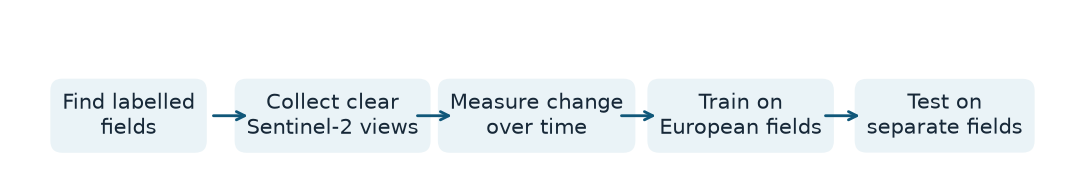

The workflow pairs crop records with Sentinel-2 imagery from the same fields. The JECAM labels stay outside development training and validation for the frozen transfer test.

**Offline presentation.** This notebook contains saved tables and embedded figures. Open it to present without running a kernel. The linked workflow notebooks and Python files contain the implementation.

[Workflow and source links](../docs/notebook_demo.md) · [Full walkthrough](SakAI_crop_classification_walkthrough.ipynb)

#### Meet the datasets

**All development fields come from Europe**, mainly Spain, France, and the Netherlands. The map shows the matched fields used in the comparisons in this demo. Paoay in Atok, Benguet is the planned application area.

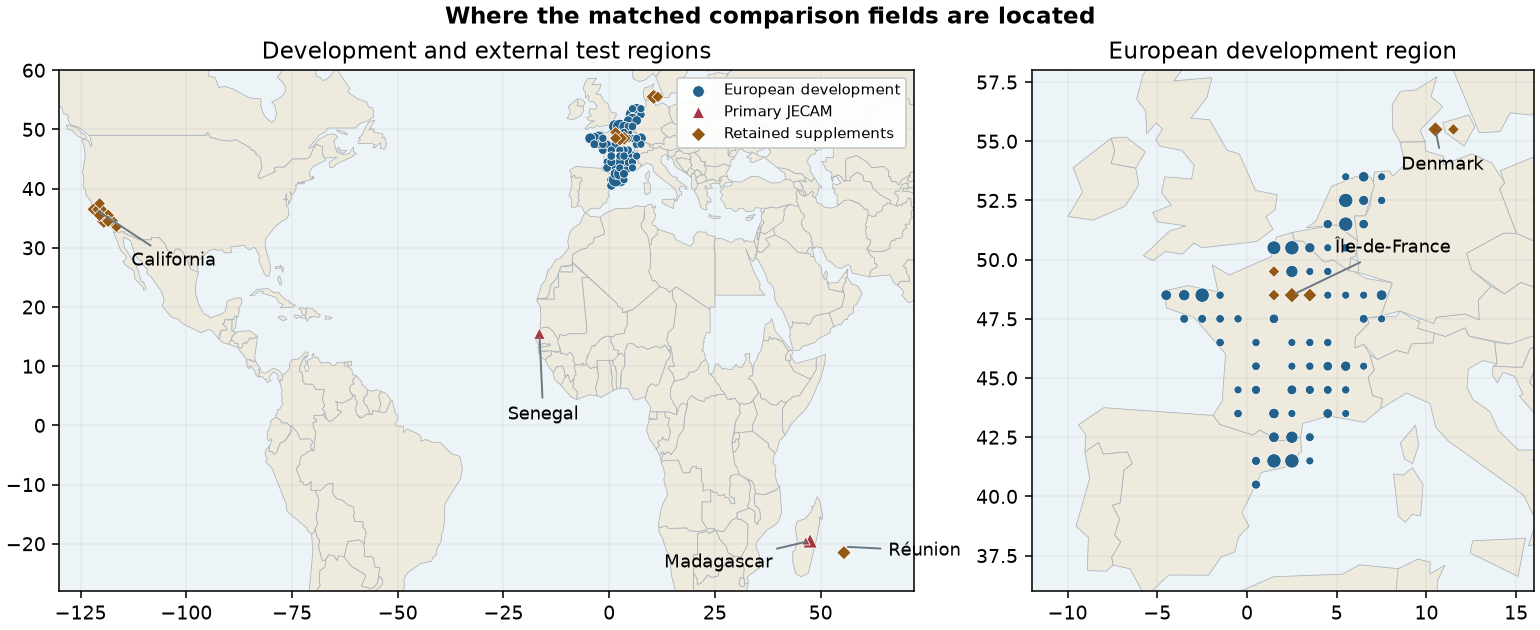

| Where | What it supplies |
| --- | --- |
| Spain, France, and the Netherlands | European development fields from Sen4AgriNet, FranceCrops, and EuroCrops |
| Madagascar’s tropical central highlands | JECAM fields with records for carrot, cabbage, and potato |
| Senegal | JECAM cabbage fields in the matched benchmark |
| California | Supplemental carrot fields from California DWR |
| Denmark | Supplemental cabbage fields from Denmark Marker |
| Île-de-France and Réunion | Supplemental CropHarvest potato fields |
| Paoay, Atok | Target area for future local checks |

**Why** · Madagascar gives us a tropical highland comparison with small fields and records of all three crops. It gives us a starting point for thinking about Paoay. Accuracy in Paoay still needs a local field test.

[Dataset register](../docs/classification_dataset_register.md) · [Final matched coverage](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/test_population_coverage.csv)

#### Use one kind of satellite imagery

We need **Sentinel-2 Level-2A surface reflectance** at the labelled fields over time. It measures how much light the ground reflects after accounting for the atmosphere. Repeated images show how the crop changes as it grows.

| Dataset | Imagery in or used by the source | How it differs from the input we need |
| --- | --- | --- |
| Sen4AgriNet | Multi-date Sentinel-2 imagery | **Same satellite.** We build half-month summaries with the same cloud rules and grid used for the other sources. |
| FranceCrops | Sentinel-2 Level-2A time series | **Same satellite and product level.** Our pipeline applies one cloud mask, grid, and half-month schedule across every source. |
| EuroCrops | Dutch parcel boundaries and crop declarations | **Field records only** in the release we used. We need to collect the Sentinel-2 time series separately. |
| CropHarvest JECAM | Sentinel-2 and Sentinel-1 in the wider package | **Includes radar.** Our classifier uses a standardized Sentinel-2 optical time series. |
| CropHarvest non-JECAM | Sentinel-2 and Sentinel-1 in the wider package | **Includes radar.** We use the same Sentinel-2 optical input as for JECAM. |
| California DWR | Crop surveys supported by imagery | We collect the standardized Sentinel-2 series for the surveyed fields. |
| Denmark Marker | Declared field boundaries and crop codes | We collect the same Sentinel-2 series for the declared fields. |

We use the **field locations listed in each dataset** to query Google Earth Engine for Sentinel-2 imagery from the reference year. The crop labels tell us what was recorded at those locations.

**Why** · One imagery archive and a shared set of processing rules give every field comparable measurements. We can skip downloading and harmonizing separate imagery packages.

[Sen4AgriNet benchmark](https://arxiv.org/abs/2204.00951) · [FranceCrops dataset](https://huggingface.co/datasets/saget-antoine/francecrops) · [EuroCrops parcel data](https://essd.copernicus.org/articles/18/4075/2026/essd-18-4075-2026.html) · [CropHarvest benchmark](https://github.com/nasaharvest/cropharvest) · [Project collection rules](../docs/collection.md)

#### Queue it, disconnect, collect it later

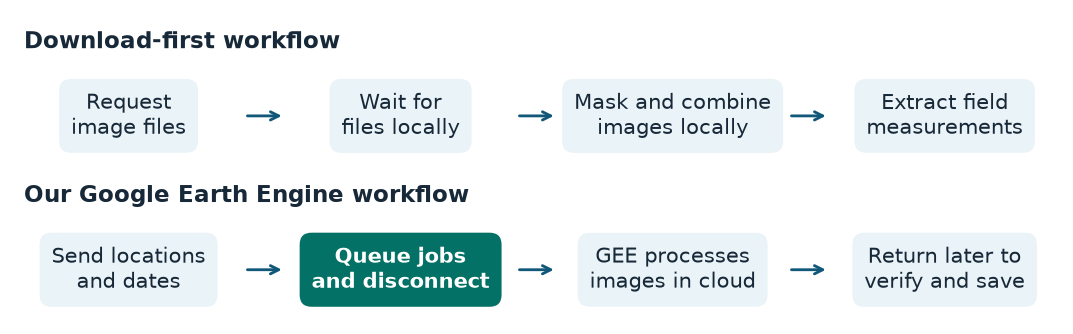

**The workaround** · Submit the jobs and save their task IDs. Once Earth Engine accepts them, the laptop can disconnect while the jobs wait in the queue and run in the cloud. Come back online later to find the finished jobs, retrieve and verify the outputs, and save them locally.

#### The Earth Engine settings that matter

| Setting | What we used | Why |
| --- | --- | --- |
| Satellite imagery | Harmonized Sentinel-2 Level-2A surface reflectance | Every field starts with the same kind of measurement of light reflected from the ground. |
| Date range | The full year in the crop record | Each request covers the recorded year. We can choose the growing months later using the saved imagery. |
| Cloud and shadow filter | Keep pixels with a cloud probability below 40%. Also remove cloud shadows and pixels with missing cloud scores. | Clouds and shadows hide the crop and can distort how green it looks. |
| Pixel grid | Line up the bands on the same 10 m grid | Each band describes the same location. Lining them up adds no new detail to the coarser bands. |
| Half-month summary | Combine images taken on the same day, then take the middle value (median) of the clear readings across days in each half-month | It gives us 24 regular time slots for the year and reduces the effect of an unusually high or low reading. |

**Why** · The laptop is free while Earth Engine works, and we can resume from saved task IDs. We transfer the results needed for the fields and can reuse the verified archive for later analysis.

[Collection guide](../docs/collection.md) · [Imagery settings](../docs/methodology.md#candidate-sampling-and-imagery) · [Saved imagery formats](../docs/reference/transport.md)

#### Which labeled fields entered the comparisons?

A **parcel** is one reference field group. These are the matched fields with usable fixed and green-up inputs in the comparisons shown here.

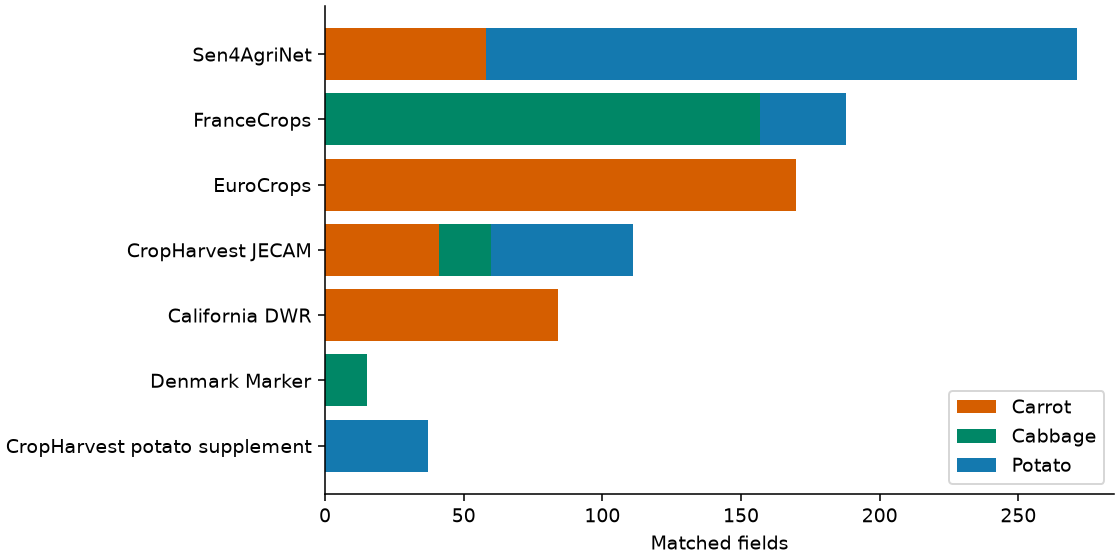

| Source | Carrot fields | Cabbage fields | Potato fields | Total fields |
| --- | ---: | ---: | ---: | ---: |
| Sen4AgriNet | 58 | 0 | 213 | 271 |
| FranceCrops | 0 | 157 | 31 | 188 |
| EuroCrops | 170 | 0 | 0 | 170 |
| CropHarvest JECAM | 41 | 19 | 51 | 111 |
| California DWR | 84 | 0 | 0 | 84 |
| Denmark Marker | 0 | 15 | 0 | 15 |
| CropHarvest potato supplement | 0 | 0 | 37 | 37 |

The European sources supply the training and validation fields. JECAM is the primary external benchmark. California carrot, Denmark cabbage, and CropHarvest potato are supplemental comparisons.

#### Collect imagery for the reference year

A Dutch carrot field declared in **2021** tells us where to look and which year to request. We query Earth Engine for Sentinel-2 imagery at that field during 2021.

**Why** · The same field can grow different crops from one year to the next. Using the reference year ties the imagery request to the year covered by the crop record.

[Collection guide](../docs/collection.md)

### Preprocessing

#### Turn satellite views into half-month summaries

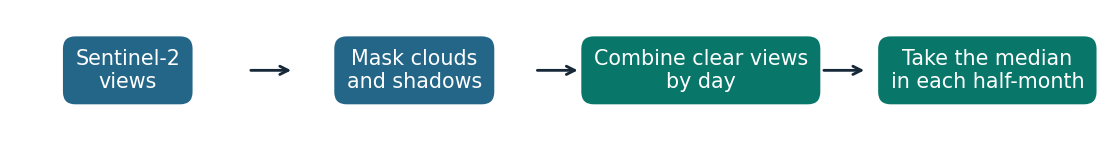

Earth Engine masks clouds, shadows, and invalid readings. It combines usable views taken on the same day, then takes the **middle value (median)** across days within each half-month. The annual archive has **24 expected half-month slots**. A cloudy slot can still have few or zero usable pixels.

**Why** · The median reduces the impact of unusually high or low readings. Regular time slots let us compare the same field across the year.

[Imagery processing rules](../docs/methodology.md#candidate-sampling-and-imagery)

#### Which half-months have enough clear imagery?

Start with this FranceCrops cabbage field tile. The two panels show real Sentinel-2 half-month images of the same spot. The grid outlines the **10 pixels selected for sampling**. Hatched cells had no usable reading in that half-month.

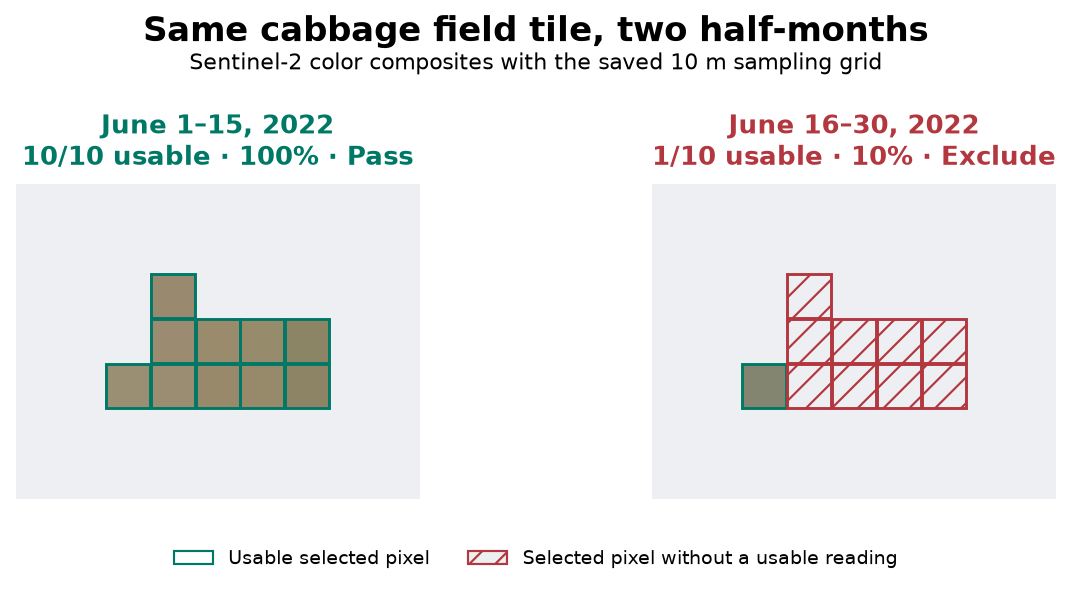

**Where the 10 m buffer comes in** · For FranceCrops, we move the field boundary **10 m inward** during collection, before choosing which pixel centers to sample. Along the edge, a pixel can include a road or a neighboring crop. Sampling farther inside reduces that mix. The audit reuses this saved set of pixels in each half-month. Sen4AgriNet uses its existing crop-mask cells.

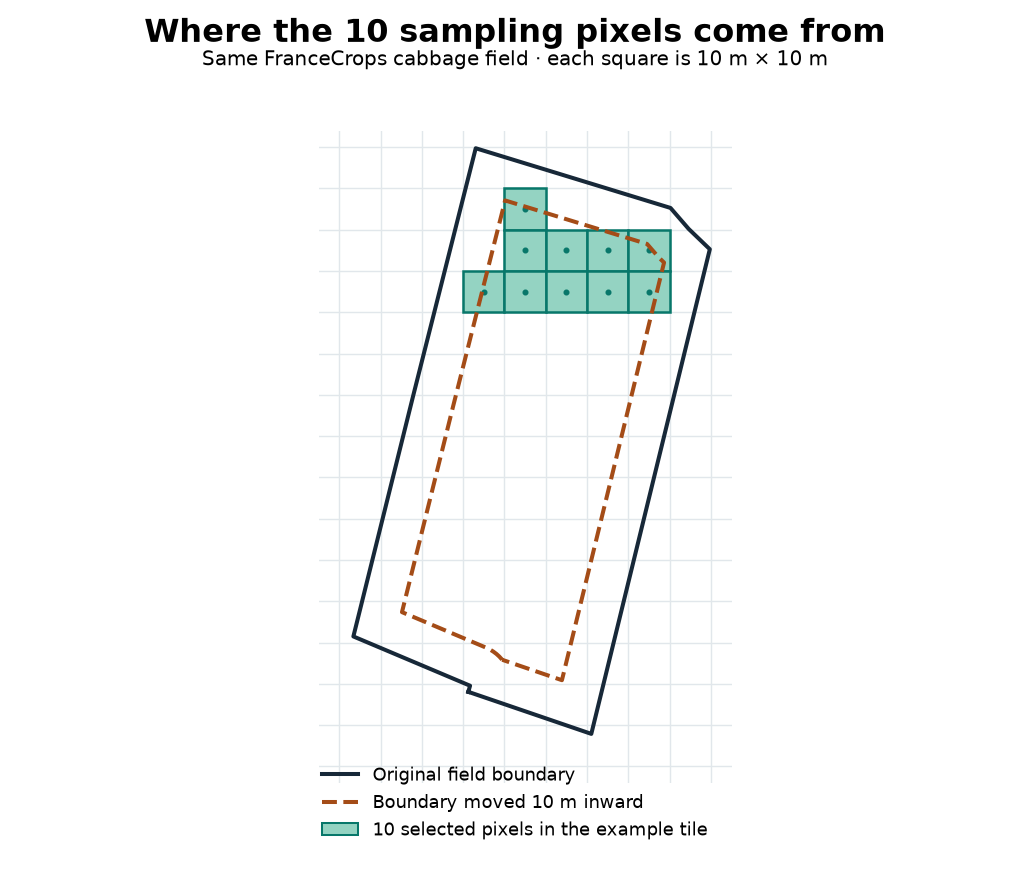

The green squares are the sample pixels in the **same tile shown in the June images**. Their centers lie inside the buffered boundary. They are the 10 pixels used as the denominator for the 80% check in both half-months.

A selected pixel is **usable** if it has at least one clear observation during the half-month and valid readings in all required bands.

**How we decide** · Divide usable pixels by selected pixels. Here, **8 of 10** are needed to reach 80%. June 1–15 passes with **10 of 10**. June 16–30 falls short with **1 of 10**, so we exclude that entire half-month for this tile, including the one usable pixel.

**How that affects window selection** · The fixed May–August window needs all eight half-months. June 16–30 leaves this tile with only **seven passing intervals**, so it contributes no complete pixels to that window. The green-up window is checked against its own eight dates.

| Across the run | Tile × half-month records |
| --- | ---: |
| Before the 80% check · all audited | 172,200 |
| After the check · passed | 131,928 |
| Below 80% · excluded from window inputs | 40,272 |

These counts come from the original imagery audit. A **tile × half-month** is one tile checked for one time slot. The excluded count includes **23,665 saved intervals with zero usable pixels**. There were **0 missing composites**.

**Why** · The imagery audit checks one half-month at a time. Window selection uses those results to find pixels with usable readings in all eight half-months of a window.

<details>
<summary>Other checks from this run</summary>

- The records with loss diagnostics contained **59,564,089 clear pixel-dates** and **132,275,610 pixel-dates lost to clouds or shadows**. A pixel-date is one selected pixel on one satellite observation date. Loss diagnostics were unavailable for **11,664 tile-intervals**.
- The external footprint overlap screen recorded **zero exclusions**.

</details>

[Sampling and buffer rules](../docs/methodology.md#candidate-sampling-and-imagery) · [Quality audit](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/quality.json) · [Observation loss by half-month](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/observation_loss_by_half_month.csv) · [Footprint overlap report](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/test_overlap_exclusions.json)

### Feature engineering

#### 1. What the model needs

For each usable satellite pixel, the Random Forest needs **72 numbers in time order**. Each number is a **feature**, a measurement the model can use to distinguish carrot, cabbage, and potato.

- **One half-month gives nine features:** five readings of reflected light, called bands, and four values calculated from those bands, called vegetation indices.
- **Four months give eight half-months.** That is **8 × 9 = 72 features** for the same pixel. Keeping them in order lets the model see how the field changes during the season.
- **During training**, we also supply the field’s recorded crop. At prediction time the model uses the same 72 features to estimate the crop.

#### 2. Turn the satellite images into numbers

Start with the cloud- and shadow-screened Sentinel-2 images from preprocessing. The bands line up on the same 10 m grid, so each reading describes the same location. For each half-month, we take the median, or middle value, of the clear readings for each band at that pixel. This gives one summary image per half-month. We build features for each selected pixel in each half-month that passes the imagery audit.

##### Read the five bands

A **band** measures light in one part of the spectrum. The archive stores the band readings as scaled numbers. We multiply them by **0.0001** to get reflectance before calculating the indices.

| Band | Light measured |
| --- | --- |
| **B3** | Green |
| **B4** | Red |
| **B5** | Red-edge, between red and near-infrared |
| **B8** | Near-infrared |
| **B11** | Shortwave-infrared |

##### Combine bands into vegetation indices

| Index | How we calculate it | What it helps describe |
| --- | --- | --- |
| **NDVI** | (B8 − B4) ÷ (B8 + B4) | How green the vegetation looks. The rise in NDVI helps guide green-up timing. |
| **NDRE** | (B8 − B5) ÷ (B8 + B5) | Vegetation changes using the red-edge band. |
| **NDMI** | (B8 − B11) ÷ (B8 + B11) | Moisture-related changes in vegetation. |
| **SAVI** | 1.5 × (B8 − B4) ÷ (B8 + B4 + 0.5) | Greenness adjusted for the influence of exposed soil. The final export adds this index. |

**Worked example** · One archived EuroCrops carrot pixel, **May 1–15, 2021**. The band readings are rounded here.

| B3 | B4 | B5 | B8 | B11 |
| ---: | ---: | ---: | ---: | ---: |
| 0.0836 | 0.1003 | 0.1135 | 0.1346 | 0.1626 |

Plug B8 and B4 into NDVI: **(0.1346 − 0.1003) ÷ (0.1346 + 0.1003) ≈ 0.146**. Here are all four index values for that pixel and half-month.

| NDVI | NDRE | NDMI | SAVI |
| ---: | ---: | ---: | ---: |
| 0.146 | 0.085 | -0.094 | 0.070 |

The initial completeness check requires **5 bands + 3 indices in all 8 half-months**, or **64 base values**. A missing value or failed interval makes the sequence incomplete for that window. The SAVI value shown in the worked example is added for each half-month in the final export, after matching and splitting. This gives **72 inputs per pixel per window**. The inputs stay in time order, from the first half-month to the eighth.

**Why** · The bands describe what the satellite sees. The indices help us read greenness and moisture-related changes. Keeping eight sets of readings in order lets the model use how the field changes across the season.

#### 3. Choose the four months

##### Why compare a fixed calendar and green-up?

A **window** is the four months of satellite readings we give the model. Imagine looking at two fields in May. One may already have a dense canopy while the other is just starting to green. The same calendar dates can show different stages of growth.

| Window | What we do | Why we use it |
| --- | --- | --- |
| **Fixed calendar** | Use **May–August** for every field. | Everyone gets the same dates. This is a simple baseline that only needs usable imagery for those months. It works best as a comparison when fields have similar growing calendars. |
| **Green-up aligned** | Use four months beginning in the month when the field shows a supported rise in greenness. | This can bring fields with earlier or later seasons closer to the same growth stage. It depends on clear views before and after the rise. |

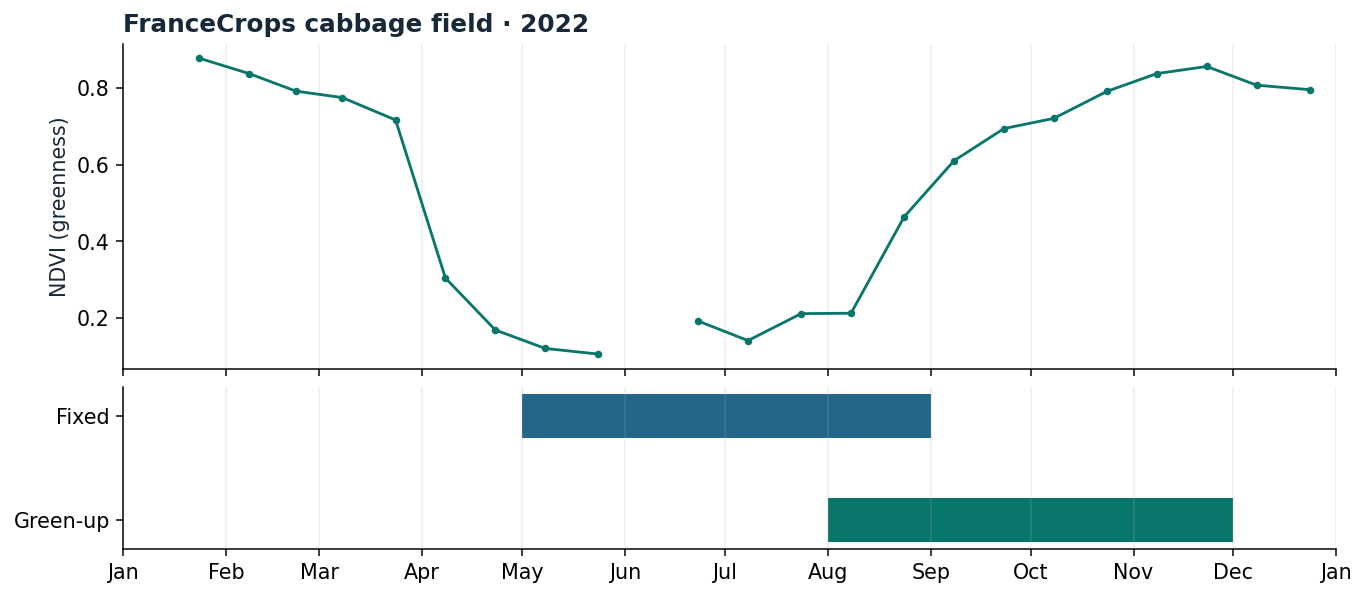

In this archived example, the fixed window begins in **May** and the aligned window begins in **August**. The plot shows half-month summaries. To find the start, the detector goes back to actual satellite dates.

##### How the detector decides that green-up happened

Think of **NDVI** as the main greenness reading. Higher values usually mean more green vegetation. **NDRE** is a second vegetation reading made from different wavelengths in the same satellite images.

1. **Look for a rise between clear views.** The detector smooths the greenness curve to find a possible rise from a low level toward a peak. It draws a line about one-fifth of the way up that rise. An actual reading at or below the line and a later reading above it bracket the start. The day between those images is uncertain.
2. **Check that the rise lasts.** The detector needs at least two usable views before the rise to establish what the field looked like. In the 30 days after the crossing, at least two more readings and at least three out of four usable readings must be above the line. Gaps between confirming readings can be at most 20 days.
3. **Check the second vegetation reading.** The typical NDRE value after the rise must increase by at least **0.02** compared with before it. Here, “typical” means the median, the middle value after sorting the readings.
4. **See if the choice is stable.** The detector tries the line at 15%, 20%, and 25% of the rise to see whether it still identifies the same growth period. The timing check normally requires the readings that bracket onset to be within 20 days. The final run also checks gaps of up to 25 days when the other evidence holds. If the evidence supports the same growth period across two neighboring months, the workflow can try both starts.

##### Two four-month examples with a checklist

Both graphs use **made-up readings** and show **August, September, October, and November** on the same scale. Each dot represents one imagined usable satellite view.

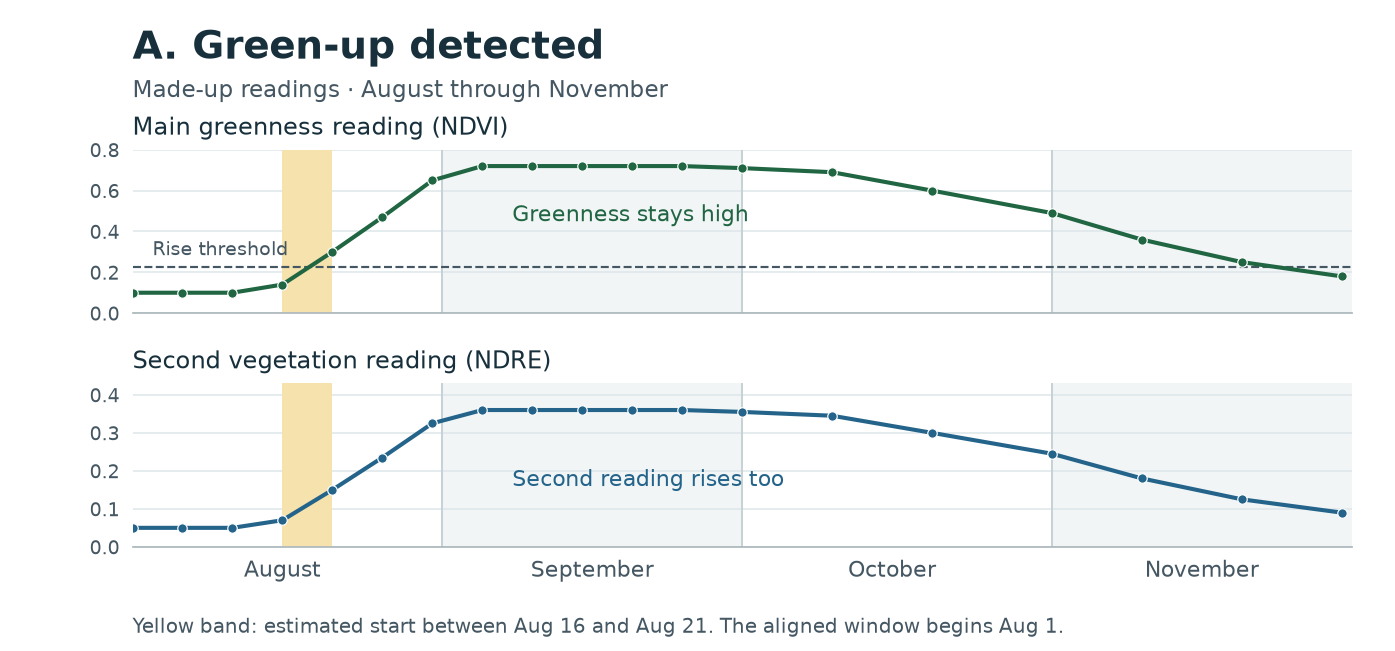

| Detector check | A. Green-up detected |
| --- | --- |
| **1. Find a rise between clear views** | **Pass.** Greenness crosses the dashed line between August 16 and 21. |
| **2. Check that the rise lasts** | **Pass.** All six readings in the next 30 days stay above the line. |
| **3. Check the second vegetation reading** | **Pass.** Typical NDRE increases by 0.31, above the required 0.02. |
| **4. Check that the timing is stable** | **Pass.** All three threshold settings point to the same August growth period. |

**Four-month aligned window:** August 1 through November 30. The yellow band shows the estimated rise in mid-August. The window begins on the first day of that month. Usable imagery is still required for all eight half-months.

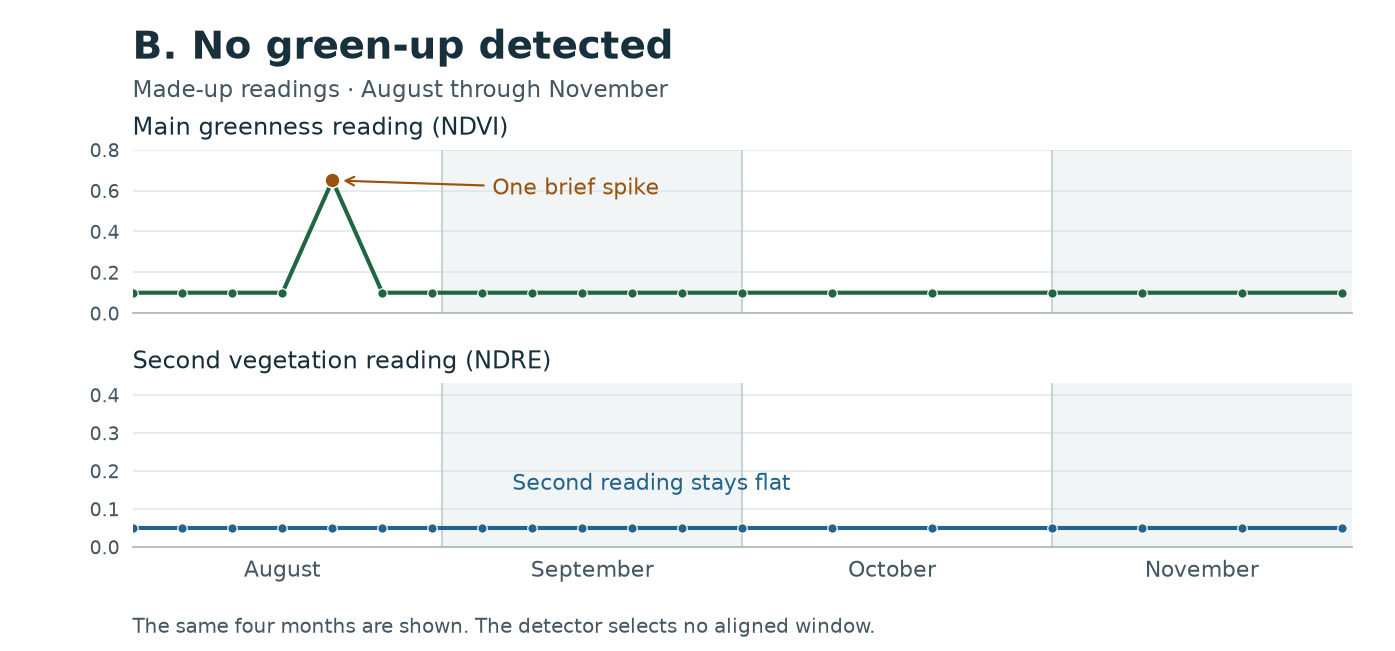

| Detector check | B. No green-up detected |
| --- | --- |
| **1. Find a rise between clear views** | **Stops here.** One high reading gives no supported rise. |
| **2. Check that the rise lasts** | **Not reached.** The graph shows the reading back at its starting level five days later. |
| **3. Check the second vegetation reading** | **Not reached.** The second reading stays flat in the graph. |
| **4. Check that the timing is stable** | **Not reached.** There is no proposed start to check. |

**No aligned window is selected.** The graph still shows the same four months for comparison.

Green-up estimates when the area started looking greener to the satellite. We still need field records to know when a crop was planted or whether the rise came from that crop, weeds, or other vegetation.

[Timing checks](../src/crop_pipeline/windows/timing_quality.py) · [Rules for nearby start months](../src/crop_pipeline/aligned_month_check.py)

##### Keep eight half-months in order

A qualifying rise supplies a candidate start. The aligned window begins on the **first day of the chosen month**. If more than one start qualifies, the workflow takes the earliest one with at least one complete usable pixel. Both windows cover **four months and eight half-month slots**.

[Feature formulas](../docs/methodology.md#classifier-features) · [Final window handoff](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/windows/windows.json) · [Saved NDVI series](../pipeline_outputs/preprocessing/external_t4tyh93t/quality/timelines/composite_timelines.csv)

#### Match locations for a fair comparison

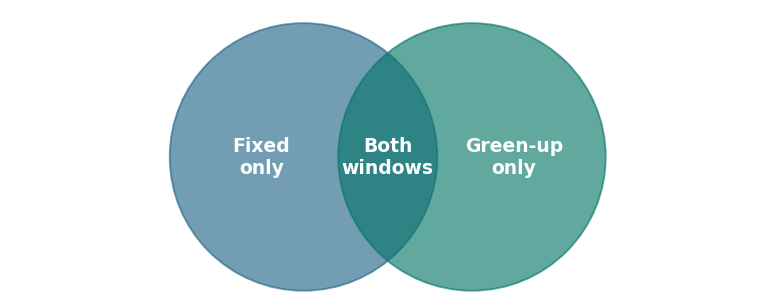

A matched pixel has complete measurements for the **same field and exact location** under both windows. The pipeline removes shared locations between different development fields within each recipe. It then keeps up to **20 shared pixels per field**.

Matching lets us ask how the choice of imagery dates affects predictions while holding the field labels and pixel locations constant.

[Final usable samples](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/usable_samples.csv) · [Shared-location audit](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/quality/development_overlap_exclusions.json)

### Split the development fields

The **629 matched European fields** were split into **472 for training** and **157 for validation**. We stratified by crop and which windows had usable data, aiming for a 75/25 split. All pixels from a field follow the same assignment. The export includes **22 matched fields from newly completed EuroCrops and FranceCrops downloads**, with 7 in training and 15 in validation.

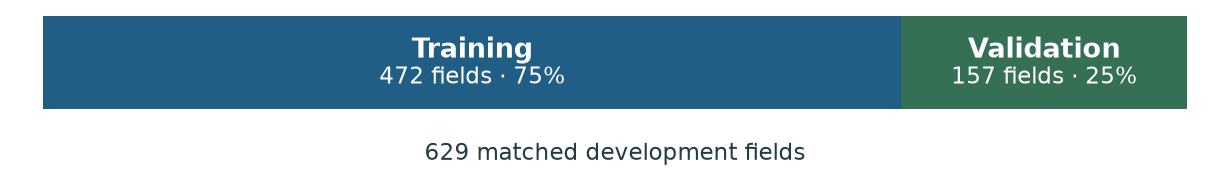

[Saved development assignments](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/development_split.json)

### See what’s ready for training and testing

| Matched set | Carrot fields | Cabbage fields | Potato fields | Total fields | Pixels |
| --- | ---: | ---: | ---: | ---: | ---: |
| Training | 171 | 118 | 183 | 472 | 8,185 |
| Validation | 57 | 39 | 61 | 157 | 2,804 |
| Primary JECAM | 41 | 19 | 51 | 111 | 489 |

Each pixel contributes **72 inputs**. The matched development data meet the training and validation sample targets for all three crops. JECAM has **19 of the 20 target cabbage fields**, and each crop falls below the external target of **400 pixels**.

[Final usable samples](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/usable_samples.csv) · [Test campaign coverage](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/test_population_coverage.csv)

## 3. Training and validation

### Load the matched inputs

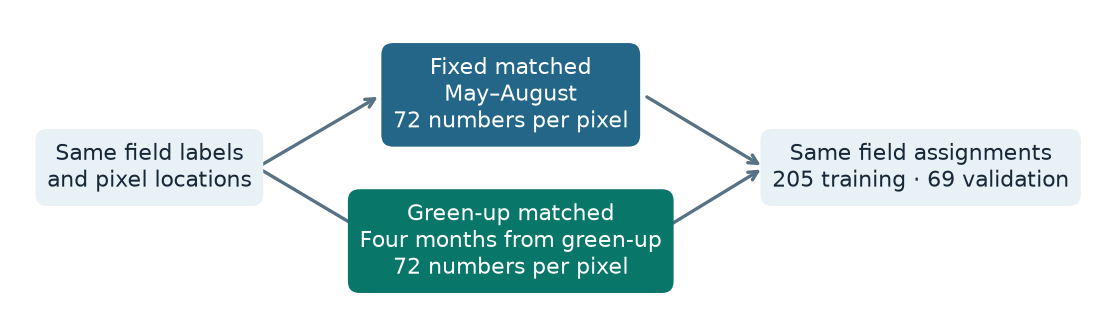

We start with the **72 numbers per pixel** from the matched feature export and the recorded crop for each field. We train one model with **fixed May–August** readings and one with **green-up-aligned** readings. Both use the same pixel locations and locked assignments, with **472 fields for training** and **157 for validation**.

**Why** · Comparing the same locations and field assignments makes it easier to see what changes when we use different imagery months.

[Saved field assignments](../pipeline_outputs/preprocessing/external_25d_resplit_t5224gy8/features/development_split.json)

### Train the Random Forests

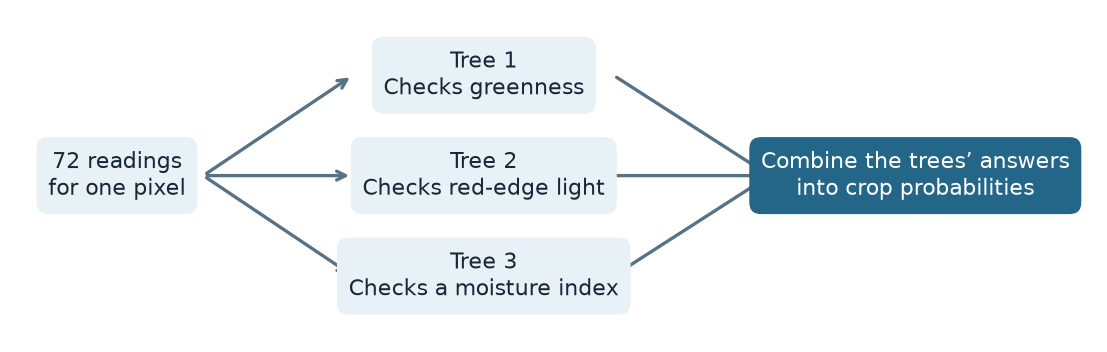

A **decision tree** asks a series of yes/no questions about a pixel’s readings. One might ask whether greenness is above a certain value in a given half-month. Each Random Forest combines **1,000 trees** to estimate how likely the pixel is to be carrot, cabbage, or potato. The picture shows three example trees.

During fitting, we give each crop the **same total weight**, then divide that weight equally among the fields of that crop. The field’s pixels share that budget in proportion to their label-confidence weights. The Random Forest uses those pixel weights as sampling probabilities for each tree’s bootstrap draw.

**Why** · Different trees can learn different patterns. Weighting keeps crops and fields with more pixels from having extra influence simply because they supplied more readings.

[Random Forest settings](../docs/methodology.md#model-selection-and-scoring) · [Training weights source](../src/crop_pipeline/training/exploratory.py)

### Validate one field at a time

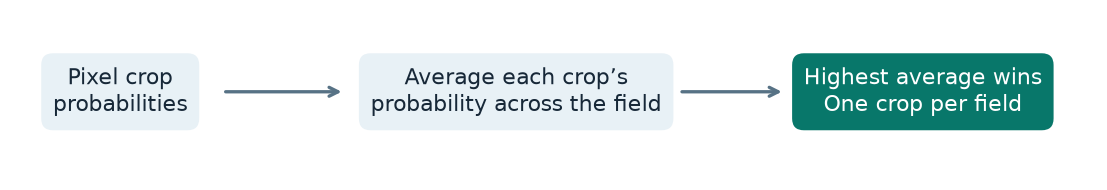

We average crop probabilities across each field’s pixels and use the highest average as the field prediction. Both models are scored on the same **157 validation fields**.

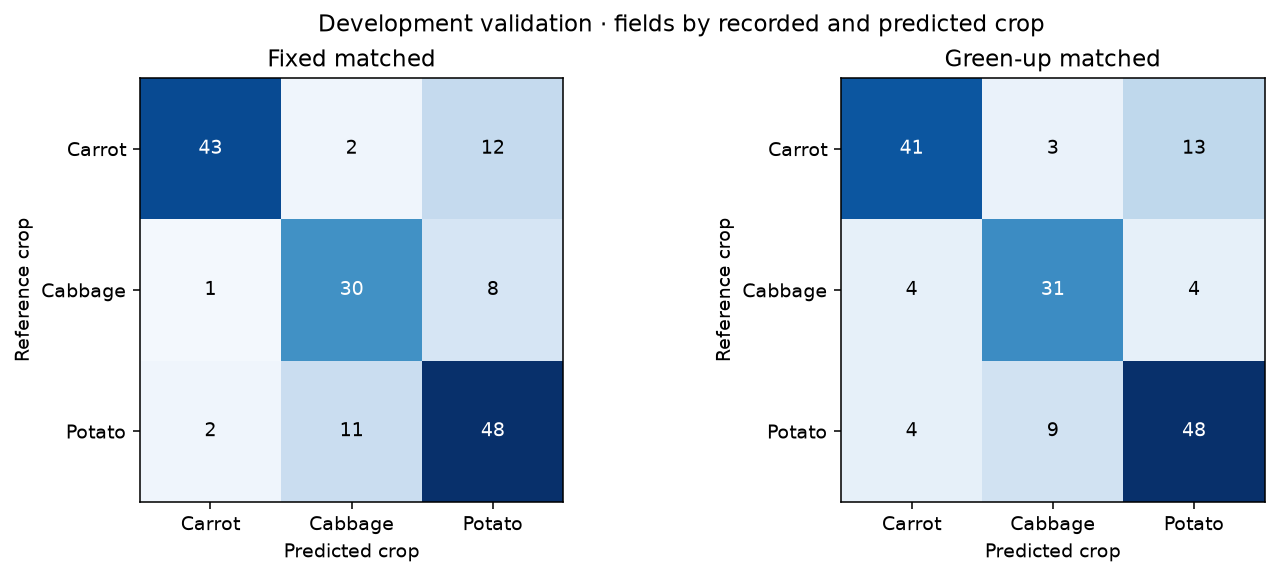

[Saved validation results](../pipeline_outputs/training/run_cf7da69b4caf/validation/validation_candidates.json)

### Compare validation scores and freeze both models

**Macro-F1** averages the three crop F1 scores. F1 balances how often a crop is found with how often predictions for that crop are correct.

| Validation metric | Fixed matched | Green-up matched |
| --- | ---: | ---: |
| Carrot | 0.835 | 0.774 |
| Cabbage | 0.732 | 0.756 |
| Potato | 0.744 | 0.762 |
| **Macro-F1** | **0.770** | **0.764** |
| Overall accuracy | 77.1% (121/157) | 76.4% (120/157) |

The models scored similarly on development validation. We froze both fitted forests before external scoring to see how they would perform on fields from a different region.

[Frozen model manifests](../pipeline_outputs/training/run_cf7da69b4caf/models/models_stage.json)

## 4. External testing

### Two questions about transfer

**Primary JECAM test · Can the models tell carrot, cabbage, and potato apart in new regions?** JECAM includes reference fields for all three crops. That lets us count both missed fields and mix-ups between crops, then compare three-crop macro-F1 and overall accuracy with the potato-only baseline.

**Supplemental campaigns · How often does the model recognize one known crop in a particular place?** Each row focuses on fields known to grow the named crop. For example, the Denmark cabbage result tells us how many known cabbage fields the model called cabbage. That measure is recall. To tell how often the model incorrectly calls another crop cabbage, we also need reference fields growing other crops.

### Establish the transfer baseline for Paoay

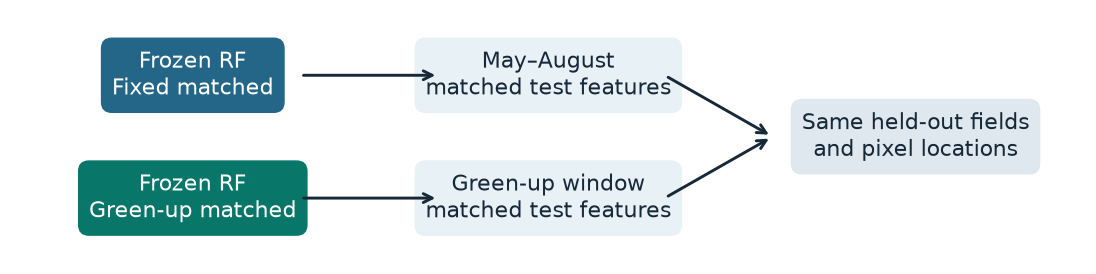

The **Fixed-Matched** forest receives May–August readings. The **Green-up Matched** forest receives its aligned four months. Both predict carrot, cabbage, or potato for the **same independent JECAM fields and pixel locations**. No JECAM labels were used to fit or validate either frozen forest.

This is the external-to-external baseline for SakAI’s upcoming application in **Paoay, Atok**. It measures how the workflow transfers from European development fields to the JECAM benchmark. JECAM had already been examined in earlier experiments, so the planned Paoay accuracy check needs independent local field records.

[External test run receipt](../pipeline_outputs/testing/run_bdac58f74ee0/scores.json) · [External scoring source](../src/crop_pipeline/training/notebook_workflow.py)

### Primary result on 111 matched JECAM fields

Both frozen models used **111 fields and 489 matched pixels**. The training-majority baseline predicts potato for every field.

| Field-level result | Fixed matched | Green-up matched | Potato-only baseline |
| --- | ---: | ---: | ---: |
| **Macro-F1** | **0.307** | **0.292** | **0.210** |
| Overall accuracy | 33.3% (37/111) | 31.5% (35/111) | 45.9% (51/111) |

| Crop | Fields | Pixels | Fixed F1 | Green-up F1 |
| --- | ---: | ---: | ---: | ---: |
| Carrot | 41 | 124 | 0.494 | 0.195 |
| Cabbage | 19 | 162 | 0.395 | 0.258 |
| Potato | 51 | 203 | 0.033 | 0.422 |

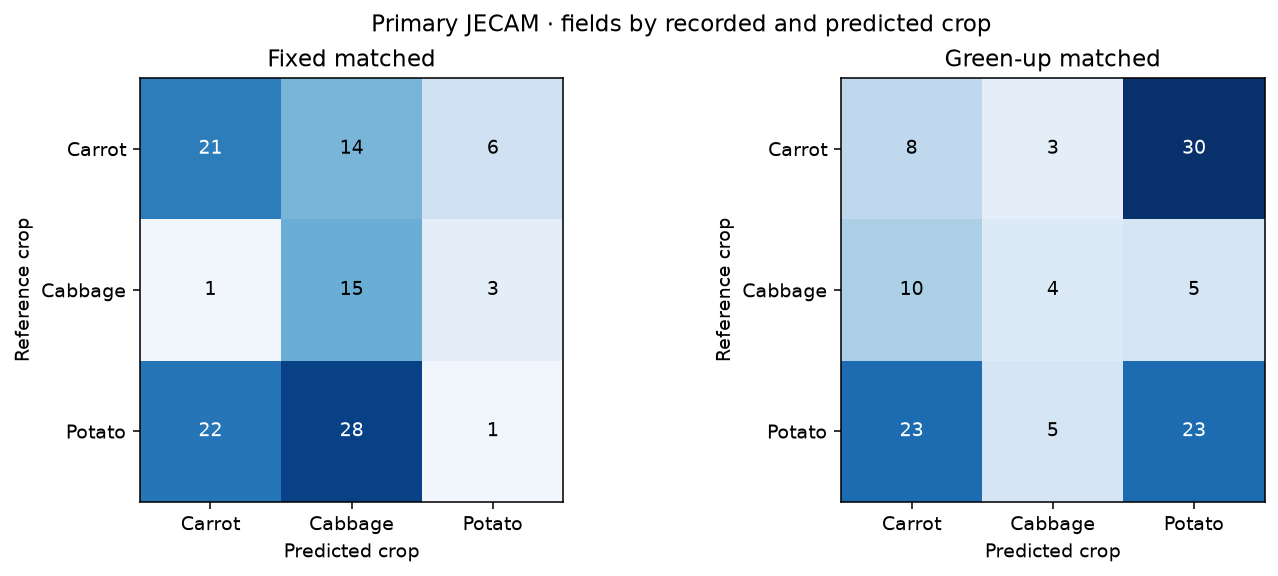

Both models exceeded the potato-only baseline on macro-F1, scored below it on overall accuracy, and fell short of the project’s **0.50 macro-F1 target**. Fixed performed better for carrot and cabbage F1. Green-up alignment performed better for potato F1. The drop from European validation to JECAM shows the challenge of geographic transfer in this study.

[Primary JECAM scores](../pipeline_outputs/testing/run_bdac58f74ee0/reports/test_scores.json) · [Training-majority baseline](../pipeline_outputs/testing/run_bdac58f74ee0/reports/majority_baseline.json)

### Supplemental single-crop campaigns

Recall is the share of reference fields for the named crop that the model correctly detected.

| Supplemental campaign | Reference crop | Matched fields | Fixed recall | Green-up recall |
| --- | --- | ---: | ---: | ---: |
| California DWR | Carrot | 84 | 35.7% (30/84) | 92.9% (78/84) |
| Denmark Marker | Cabbage | 15 | 66.7% (10/15) | 86.7% (13/15) |
| CropHarvest non-JECAM, Île-de-France and Réunion | Potato | 37 | 91.9% (34/37) | 70.3% (26/37) |

The comparisons below use recall for the same crop and model on each test.

The models may have recognized some crops more easily in places with growing conditions or crop calendars closer to those in their European training data. The fixed model detected potato in **27 of 28 Île-de-France fields (96.4%)**, compared with **1 of 51 JECAM potato fields (2.0%)**. The green-up model detected cabbage in **86.7%** of the Denmark fields and **21.1%** of the JECAM cabbage fields.

[Saved supplemental predictions](../pipeline_outputs/testing/run_bdac58f74ee0/predictions) · [External results by campaign](../pipeline_outputs/testing/run_bdac58f74ee0/reports/diagnostics/results.md)

## 5. Local adaptation

### Can adding local fields improve transfer?

The main comparison uses the **same 88 held-out JECAM fields** (35 carrot, 12 cabbage, 41 potato). The frozen green-up model uses 472 European training fields. The 1× refit adds 23 JECAM fields from Madagascar and Senegal (6 carrot, 7 cabbage, 10 potato).

| Green-up matched model | Local fields in fitting | Macro-F1 | Carrot F1 | Cabbage F1 | Potato F1 |
| --- | ---: | ---: | ---: | ---: | ---: |
| Frozen baseline | 0 | 0.261 | 0.179 | 0.200 | 0.404 |
| Adapted at standard weight (1×) | 23 | 0.657 | 0.453 | 0.800 | 0.718 |

**Split verification.** All 111 matched JECAM fields were accounted for. No original field boundaries intersected across the two groups. Source parcel IDs checked independently of year and sampled pixel locations also had no overlap. The 500 m centroid blocks were disjoint within each country. The nearest original adaptation and holdout boundaries were about 530 m apart in Madagascar and 528 m apart in Senegal.

**How weighting worked.** At 1×, each crop has the same total sampling weight, and every field of a given crop has the same weight. For 2×–4×, the multiplier applies to local fields after balancing the pooled training set. European fields keep their relative weights. The final weights are normalized together to mean one, so extra local weight also changes the final crop shares. All four refits reproduced the archived predictions for every held-out field.

### Exploratory weighting

All four refits used the same **23 local training fields** and the same **88 held-out JECAM fields**. Only the local field weight changed.

| Local field weight | Macro-F1 | Carrot F1 | Cabbage F1 | Potato F1 |
| --- | ---: | ---: | ---: | ---: |
| 1× (standard-weight reference) | 0.657 | 0.453 | 0.800 | 0.718 |
| 2× | 0.657 | 0.453 | 0.800 | 0.718 |
| 3× | 0.702 | 0.509 | 0.857 | 0.740 |
| 4× | 0.702 | 0.509 | 0.857 | 0.740 |

The 3× and 4× refits tied at **0.702 macro-F1**. This single split on previously examined JECAM data leaves the best weight uncertain. In this experiment, “local” refers to Madagascar and Senegal. Paoay needs its own adaptation fields and independent accuracy check.

[Weight comparison](../pipeline_outputs/testing/run_ca5c900c415b/jecam_weight_comparison.csv) · [Adaptation and holdout split](../pipeline_outputs/testing/run_ca5c900c415b/jecam_site_split.csv) · [Verification source](../tools/verify_jecam_adaptation.py)


## 6. Paoay application

### Audit the imagery for the whole barangay

We used the indicative **Barangay Paoay, Atok** outline to test two four-month windows in each year. The audit applies the Sentinel-2 cloud and shadow masks over the whole barangay. The weakest bin is the least clear of the eight half-months. The all-eight column counts the area with a clear observation in every bin.

| Year | Jan–Apr weakest bin | Jan–Apr all eight | May–Aug weakest bin | May–Aug all eight |
| --- | ---: | ---: | ---: | ---: |
| 2024 | 99.8% | 99.7% | 7.7% | 0.2% |
| 2025 | 81.2% | 78.3% | 0.0% | 0.0% |
| 2026 | 29.6% | 29.4% | 0.0% | 0.0% |

January–April 2024 had the strongest imagery coverage. May–August is the fixed model’s training season, and none of the checked May–August windows met the 80% whole-barangay threshold in all eight bins.

[Whole-barangay imagery audit](../data/pipeline_work/paoay/whole_barangay/window_audit.csv) · [Indicative Paoay boundary](https://www.openstreetmap.org/relation/20601702)

### Apply the frozen baseline on mapped farmland

Both Paoay maps use the **Fixed-Matched Random Forest baseline** from the final development run, trained on 472 European fields and validated on 157. This is the same frozen model used for the fixed-window external baseline.

The conservative Dynamic World rule found zero pixels with enough repeated crop support for this period. The demo uses the published **SEA_Cropland10 2024** layer to restrict where the frozen model can make predictions. Dynamic World remains available as land-cover context. The cropland layer marked **83,729 pixels** in Paoay, and **83,466** had imagery across all eight bins. Every bin passed the 80% coverage gate over the mapped farmland.

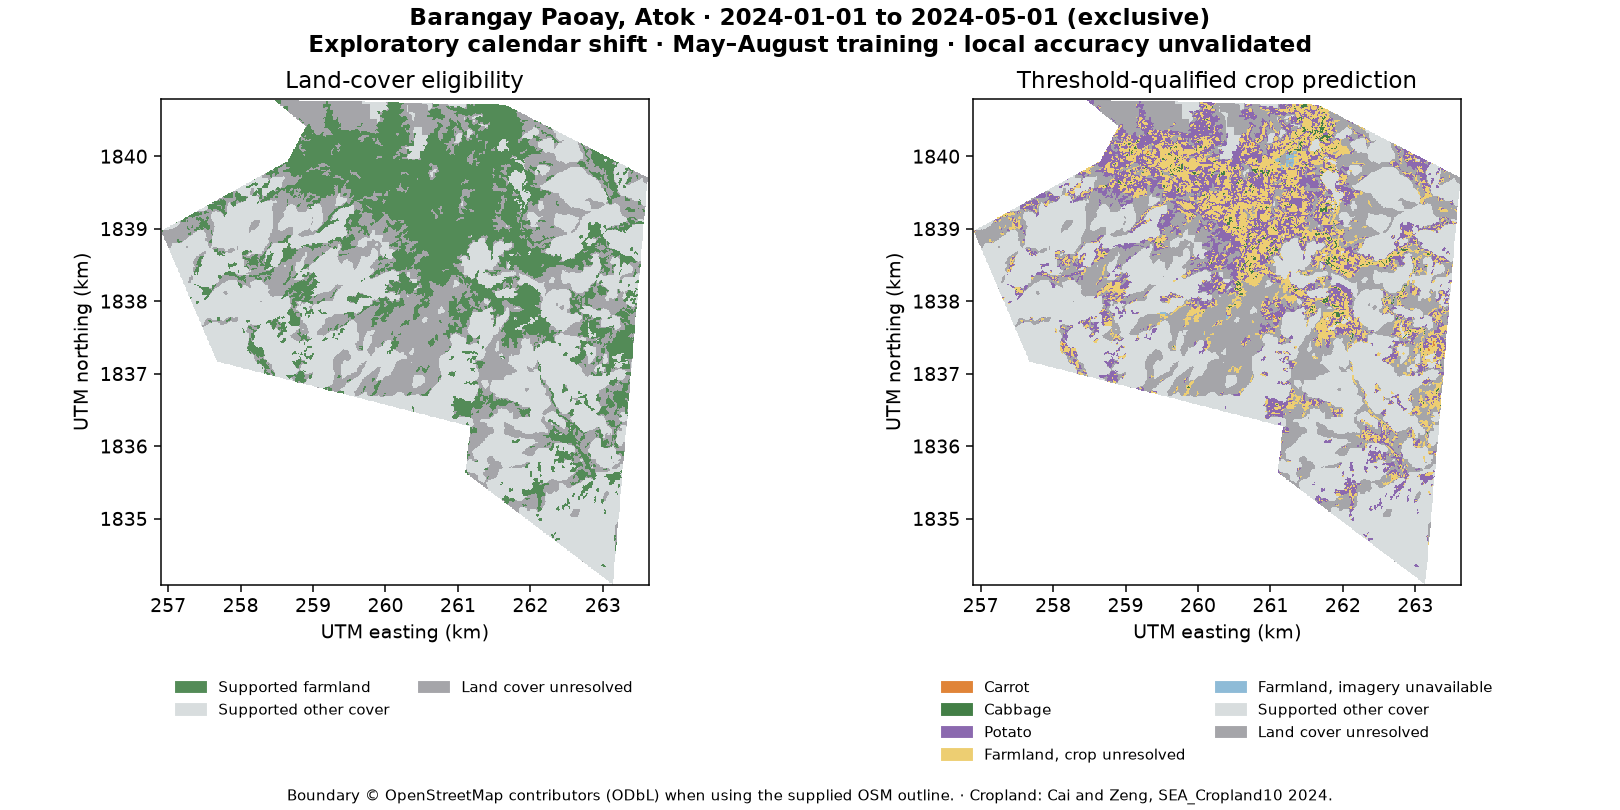

| Mapped farmland outcome | Pixels | Area (ha) |
| --- | ---: | ---: |
| Threshold-qualified carrot prediction | 97 | 0.97 |
| Threshold-qualified cabbage prediction | 2,344 | 23.44 |
| Threshold-qualified potato prediction | 40,989 | 409.89 |
| Farmland, crop unresolved | 40,036 | 400.36 |
| Farmland, imagery unavailable | 263 | 2.63 |

### Why the Paoay map is exploratory

**Calendar mismatch.** The fixed model learned from **May–August** imagery. We mapped **January–April 2024** because 99.7% of the barangay had a clear observation in all eight half-months, compared with 0.2% for May–August 2024. Clear images let us make the map. Crops can be at different stages of growth in these two periods, so the January–April readings may differ from the patterns the model learned.

**Local accuracy remains unvalidated.** A **threshold-qualified crop prediction** means the top mean forest probability reached at least **0.60** and led the next crop by at least **0.10**. These cutoffs determine when the map assigns a crop label. Checking whether those labels are correct requires independent Paoay field observations dated to January–April 2024. The area totals show how much farmland the model assigned to each crop. Actual planted area still needs field evidence.

### Zoom in to the professor’s study boundary

We reran the farmland-first map on the **Region of Interest** from the professor’s KMZ and kept the seven smaller reference outlines for field review. The zoomed view covers **411.67 ha**. Hover or tap a dashed red reference area to read its original KMZ crop notes. The map shows the model prediction and score separately.

[Open the interactive study-area map](../data/pipeline_work/paoay/professor_boundary/maps/bb6a580ebcdd12625eb5/paoay-study-area-qualified.html) · [Study-area GeoTIFF and source handoff](../data/pipeline_work/paoay/professor_boundary/maps/bb6a580ebcdd12625eb5/map_handoff.json)

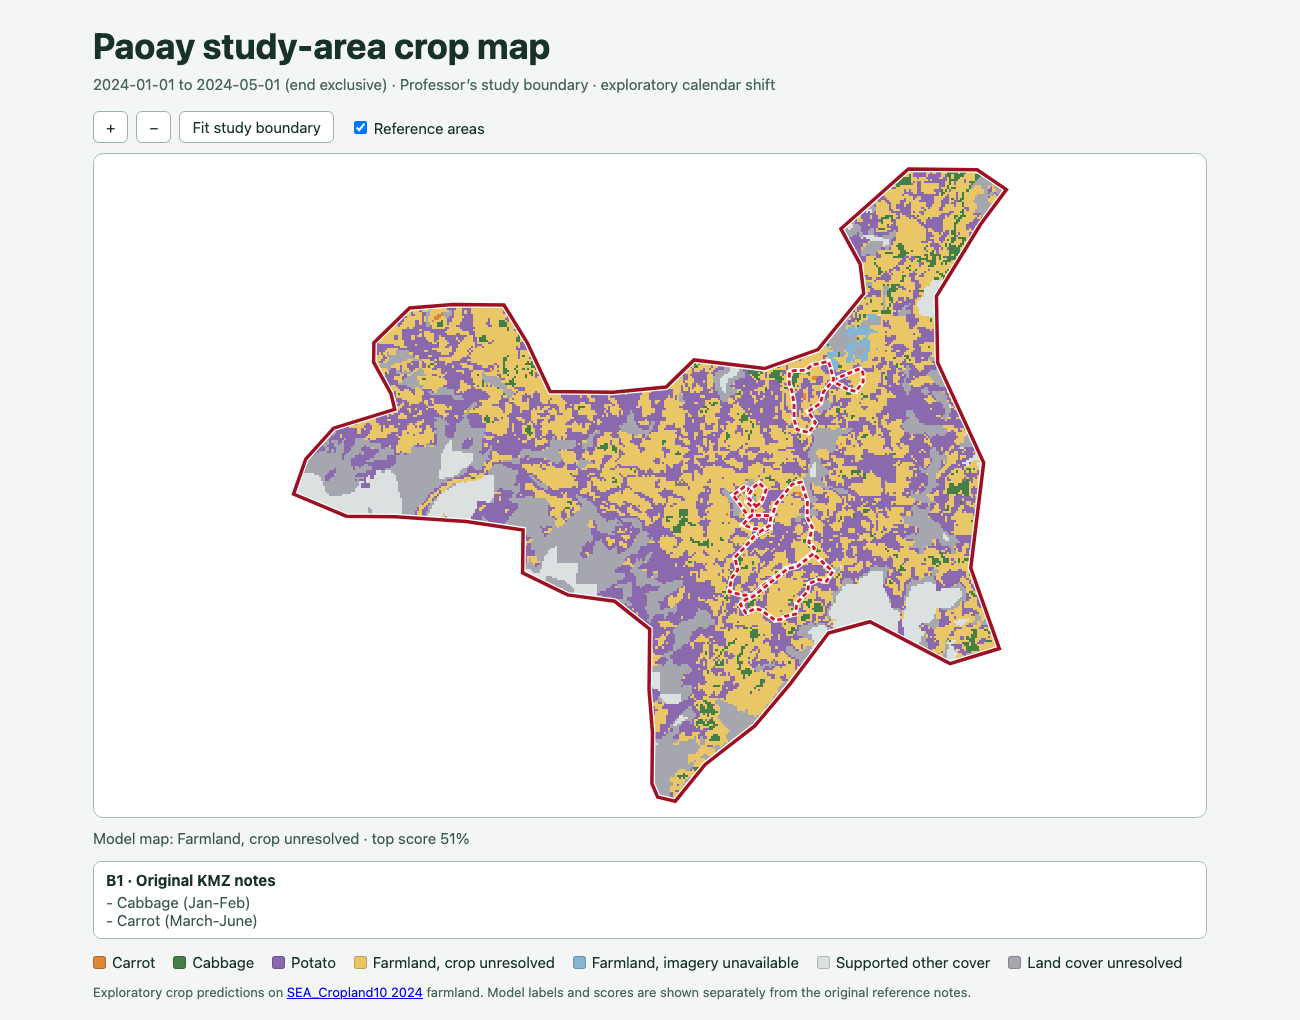


## 7. Limitations and next steps

The January–April 2024 Paoay map remains unvalidated.

### What limits transfer to another region?

| Limitation | Effect on interpretation |
| --- | --- |
| **Crop and source confounding** | All 157 matched development cabbage fields come from FranceCrops. EuroCrops supplies 170 of 228 development carrot fields. A forest can learn source-specific growing conditions, field sizes, annotation practices, or imagery patterns along with crop signals. Crop and source effects are difficult to separate in this design. |
| **Reference-date uncertainty** | A crop record can identify a crop and year or a date of observation. The crop’s planting and harvest dates and its presence throughout all eight half-months can still be uncertain. Green-up estimates vegetation onset from imagery and may capture a different cycle from the labelled crop. |
| **Geographic differences** | Elevation, rainfall, temperature, field size, crop varieties, planting calendars and management differ across the European fields, Madagascar, Senegal and Paoay. The campaign comparisons cannot isolate the effect of distance or any one growing condition. |
| **Fields lost to strict imagery requirements** | Cloud and shadow masking, the 80% interval gate, complete eight-bin pixel sequences and matching both windows reduce coverage. JECAM had 148 usable fixed-window fields, 120 usable green-up fields, and 111 fields with shared usable pixels. The matched result covers 19 cabbage fields, and each crop is below the 400-pixel target. Fields with frequent clouds or short observable crop cycles can be underrepresented. |

The transfer scores describe the eligible JECAM fields. Dated independent Paoay field records are needed to measure how the model performs locally.

[Saved external diagnostics](../pipeline_outputs/testing/run_bdac58f74ee0/reports/diagnostics/results.md) · [Paoay field observations](../docs/paoay_workflow.md#field-observations)

### Check the map with independent Paoay fields

The external tests establish a transfer baseline. This application shows how to turn it into a whole-barangay map with explicit limits on land-cover and imagery eligibility. The Paoay field check needs dated crop observations and boundaries from the mapped season. A separate set of independent local fields can then measure crop-model accuracy and check where the land-cover mask misses farmland.

[Reproduce the farmland workflow](paoay/08_whole_barangay_farmland.ipynb) · [Map source](../src/crop_pipeline/paoay/whole_barangay.py) · [Map run and provenance](../data/pipeline_work/paoay/whole_barangay/maps/3c448502b95cfb5f6e49/map_handoff.json) · [SEA_Cropland10 source](https://doi.org/10.5281/zenodo.19303406) · [Field observation protocol](../docs/paoay_workflow.md#field-observations)

1. **Collect local crop references.** Record crop identity, field boundaries, and observation dates that can be matched to the satellite imagery.
2. **Adapt with a small local training set.** Reserve separate Paoay field blocks for evaluation before using any local records to refit the model.
3. **Evaluate independently.** Score the frozen and adapted models on the same held-out Paoay fields to measure local accuracy and the effect of adaptation.

**Key takeaway.** A crop model trained in one region may generalize poorly to another. The exploratory JECAM result suggests that a small set of regional training fields can improve classification and gives SakAI a specific approach to test in Paoay.


## Technical appendix

### Feature and classifier comparisons on the final development split

We reran these comparisons on **472 matched training fields** and scored every variant on the **same 157 validation fields**. Both window methods use the same field assignments. Macro-F1 gives carrot, cabbage, and potato equal weight.

| Experiment | What changed | Fixed matched | Green-up matched |
| --- | --- | ---: | ---: |
| Baseline RF | 72 interval inputs | 0.770 | 0.764 |
| Shape only | 48 changes, slopes, and other shape measurements | 0.820 | 0.734 |
| Intervals + shape | 72 interval inputs plus 48 shape measurements | 0.790 | 0.750 |
| Bands only | 40 band readings | 0.734 | 0.748 |
| Indices only | 32 vegetation indices | 0.774 | 0.739 |
| One half-month | 9 inputs from the fourth half-month | 0.681 | 0.632 |
| RF tuning | Settings selected using geographically grouped training folds | 0.770 | 0.769 |
| RBF SVM | 72 inputs and preset settings | 0.793 | 0.779 |
| XGBoost | 72 inputs and preset settings | 0.790 | 0.738 |
| Field-median RF | 72 median measurements per field | 0.721 | 0.712 |

The highest validation macro-F1 came from **Shape only** for fixed and **RBF SVM** for green-up. The RF tuning check used five geographically grouped folds within training. It selected minimum leaf size 8 for fixed and minimum leaf size 4 for green-up.

[Validation macro-F1 results](../pipeline_outputs/training/run_bc1834d2ac7d/validation_macro_f1.csv) · [Settings and field predictions](../pipeline_outputs/training/run_bc1834d2ac7d/validation_details.json)

### Two exploratory variants on the 111-field JECAM benchmark

We refit the same two designs used in the earlier external comparison and scored them on the **same 111 fields and 489 matched pixels** as the current frozen baseline. The designs were specified before this scoring run.

| Window | Frozen baseline macro-F1 | Exploratory model | Exploratory macro-F1 |
| --- | ---: | --- | ---: |
| Fixed matched | 0.307 | XGBoost | 0.297 |
| Green-up matched | 0.292 | RF tuning | 0.302 |

JECAM stayed outside fitting and validation for these variants. It had already been examined in earlier experiments, so these scores describe the historical benchmark. The upcoming Paoay accuracy check will use independent local fields.

[Exploratory JECAM scores](../pipeline_outputs/testing/run_d6ce2e68cd80/jecam_macro_f1.json) · [Earlier experiment archive](../pipeline_outputs/training/run_81de4b6717e9/matched_validation_experiments.json)
